# Daily residual reversal: gross/pre-fee research results

**Project convention: report gross/pre-fee performance only.** No assumed fee schedule or trading-cost deduction enters the tables and plots below. Original frozen artifacts retain old sensitivity scenarios for provenance; they are superseded as the reporting default.

This notebook reads local saved results and submits no trades. Use the **TDA (conda)** kernel. See the [experiment guide](experiments/equity_residual_backtest/README.md), [diagnostic explanation](experiments/equity_residual_diagnostics/README.md), and [recommended next research step](EQUITY_NEXT_STEPS.md).

## What was tested

- Thirty selected stocks at 1x gross target, approximately half equity long and half short.
- Dollar + SPY-beta neutrality, compared with the same constraints plus three residual-PC exposures.
- Exposure and inverse-variance estimates from 120 sessions ending **before** signal day t.
- Signal: one-day adjusted close-to-close log returns at t. Cross-sectional WLS positions are proportional to minus W times the residuals.
- Entry proxy: next vendor daily-bar raw open. Exit proxy: that session's raw close, with exact fractional-dollar allocations idealized.
- No position caps, ranking, economic signal threshold, or parameter search. Later-period settings matched development.

The signal, estimation window, and future holding interval are separate. Returns before entry are not earned by the original strategy. Vendor bar opens/closes have not been independently verified as regular-session auction prices. Gross reporting does not alter that timing limitation.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
project_candidates = [Path.cwd(), Path.cwd() / "Senior-Fall" / "TDA_Research", *Path.cwd().parents]
project = next(p for p in project_candidates if (p / "START_HERE.md").is_file() and (p / "equity").is_dir())
root = project / "equity"
experiment = root / "experiments" / "equity_residual_backtest"
report = experiment / "gross_report"
diag = root / "experiments" / "equity_residual_diagnostics"
summary = json.loads((experiment / "evaluated" / "summary.json").read_text())
performance = pd.read_csv(report / "performance.csv")
print("Reporting: gross/pre-fee only")
print("Models:", summary["specification"]["models"])
print("Exposure lookback:", summary["specification"]["training_sessions"], "sessions")
print("2024 onward has been evaluated; it is no longer an untouched temporal holdout.")

Reporting: gross/pre-fee only
Models: ['SPY_only', 'SPY_plus_3_residual_PCs']
Exposure lookback: 120 sessions
2024 onward has been evaluated; it is no longer an untouched temporal holdout.


## Gross results

This specification did not establish a positive gross reversal edge. Both later-period point estimates are negative. A weak average does not mean every year lost money.

Gross returns are simulated stock P&L divided by starting equity. The portfolio target is reset to 1x gross each day. CAGR compounds returns with a 252-session annualization; Sharpe is relative to zero. Development spans June 28, 2016–December 29, 2023 (1,890 sessions); evaluation spans January 2, 2024–October 27, 2026 (708 sessions).

,period,model,days,mean_daily_bps,sharpe_vs_zero,compound_annual_growth,annualized_volatility,max_drawdown
0,development,SPY_only,1890,0.4966,0.1835,0.0102,0.0682,-0.2297
1,development,SPY_plus_3_residual_PCs,1890,-0.3465,-0.1731,-0.0100,0.0504,-0.1998
2,evaluation,SPY_only,708,-1.2908,-0.4857,-0.0342,0.0670,-0.1910
3,evaluation,SPY_plus_3_residual_PCs,708,-0.6459,-0.3072,-0.0175,0.0530,-0.1601


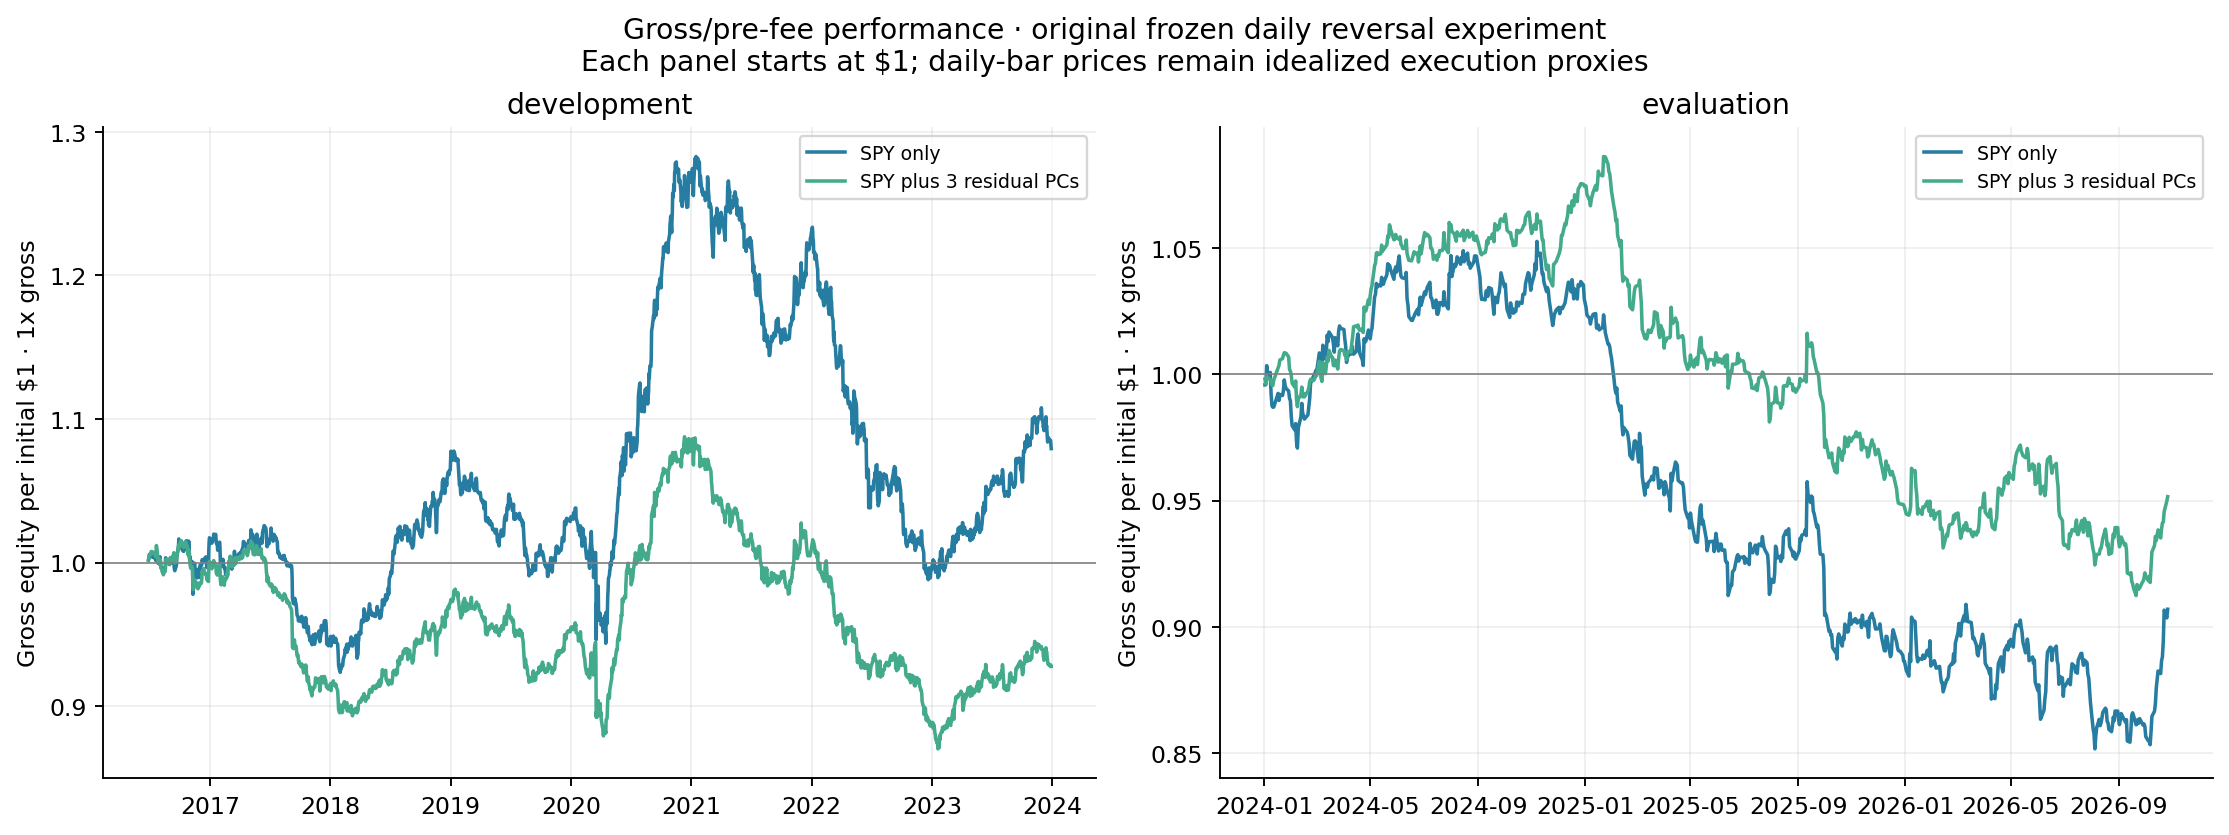

In [2]:
cols = ["period", "model", "days", "mean_daily_bps", "sharpe_vs_zero", "compound_annual_growth", "annualized_volatility", "max_drawdown"]
display(performance[cols].round(4))
display(Image(filename=str(report / "01_gross_equity.png")))

## Uncertainty and the effect of additional constraints

Evaluation annualized gross volatility fell from about 6.7% to 5.3% with the three residual-PC constraints. This did not produce a positive average gross return. Approximate five-lag Newey–West intervals include zero for both models and for their paired mean-return difference. These intervals are conditional on this experiment and do not adjust for arbitrary research choices.

PCA's variance-reconstruction objective is different from predicting reversal. A losing strategy does not by itself establish that PCA estimated risk badly or that another representation will create alpha.

In [3]:
display(performance[["period", "model", "mean_daily_bps", "mean_daily_bps_hac95_low", "mean_daily_bps_hac95_high"]].round(3))
display(pd.DataFrame(summary["paired_comparison"]).round(3))

,period,model,mean_daily_bps,mean_daily_bps_hac95_low,mean_daily_bps_hac95_high
0,development,SPY_only,0.497,-1.346,2.339
1,development,SPY_plus_3_residual_PCs,-0.347,-1.767,1.074
2,evaluation,SPY_only,-1.291,-4.514,1.933
3,evaluation,SPY_plus_3_residual_PCs,-0.646,-3.228,1.936


,period,pca_minus_spy_mean_daily_bps,paired_hac95_low_bps,paired_hac95_high_bps
0,development,-0.843,-2.089,0.402
1,evaluation,0.645,-1.414,2.704


## Gross calendar-period returns

Both models had positive gross years, including 2018, 2020, 2023, and 2024. These observations do not identify a regime we could reliably select beforehand. The first and last calendar years are partial periods and the bars are not annualized. No economic cause for the year-to-year differences has been established.

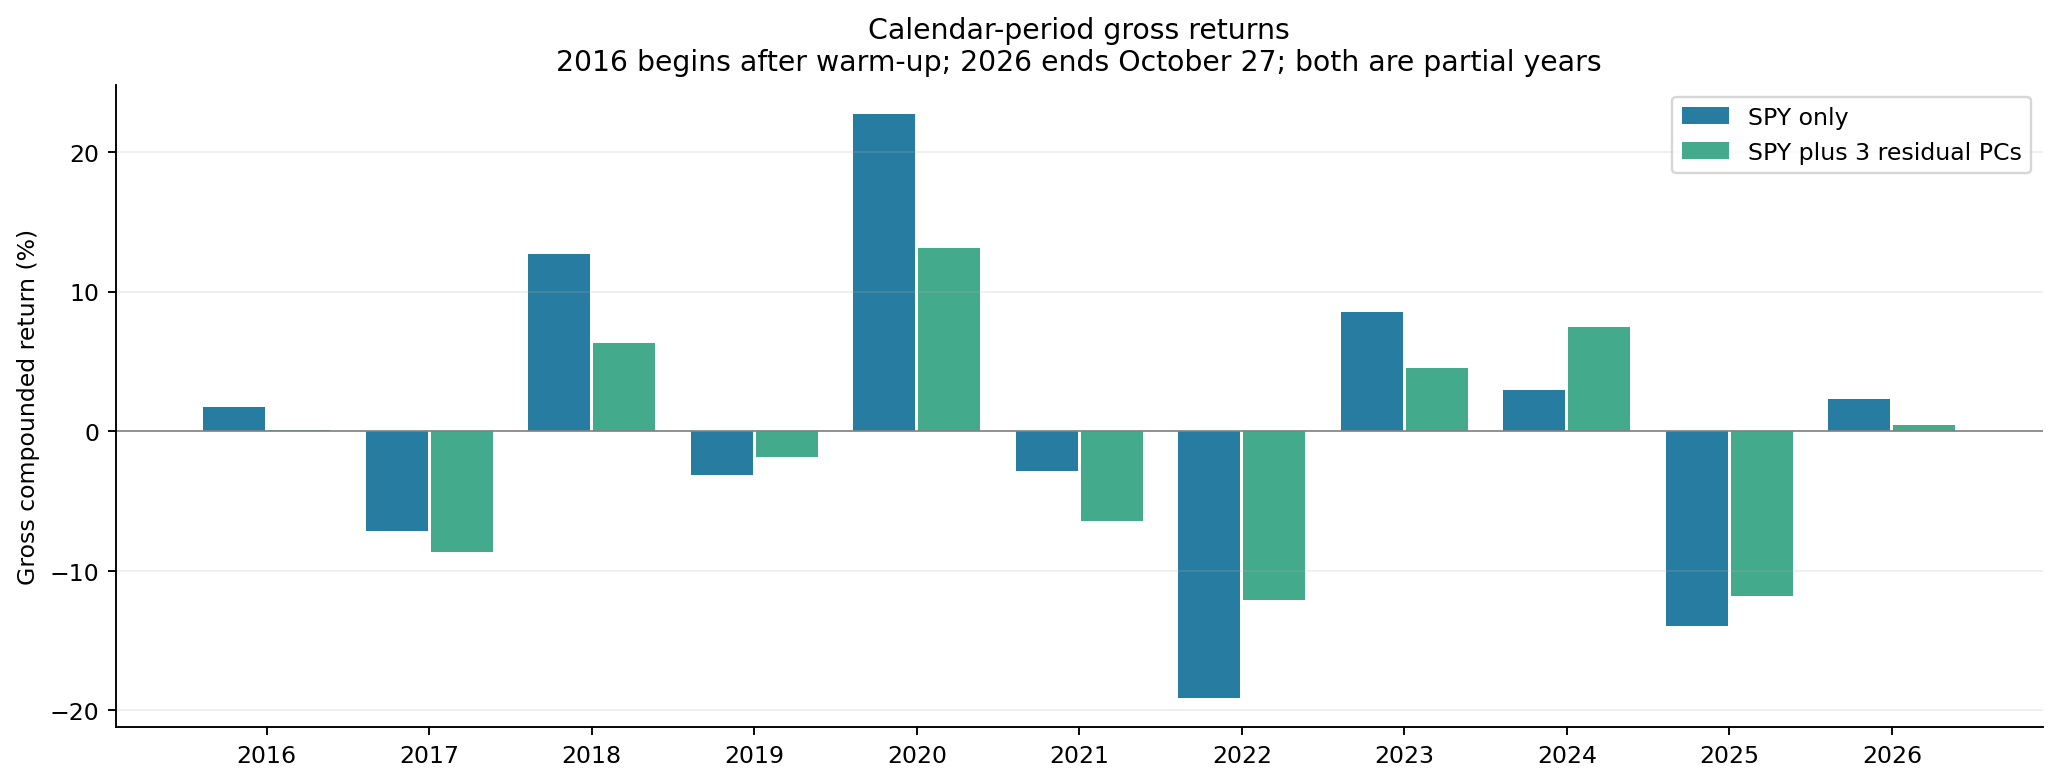

,period,model,year,days,gross_compound_return
0,development,SPY_only,2016,130,0.0173
1,development,SPY_only,2017,251,-0.0713
2,development,SPY_only,2018,251,0.1267
3,development,SPY_only,2019,252,-0.0312
4,development,SPY_only,2020,253,0.2271
5,development,SPY_only,2021,252,-0.0282
6,development,SPY_only,2022,251,-0.1913
7,development,SPY_only,2023,250,0.0853
8,development,SPY_plus_3_residual_PCs,2016,130,0.0008
9,development,SPY_plus_3_residual_PCs,2017,251,-0.0867


In [4]:
display(Image(filename=str(report / "02_gross_annual_returns.png")))
annual = pd.read_csv(report / "annual_returns.csv")
display(annual.round(4))

## Construction and timing checks

Weighted neutrality, pure-factor zero trades, basis invariance, hypothetical reversal sign, prior-window timing, and future-suffix invariance checks passed. The targets satisfy their estimated exposure constraints to numerical precision. The maximum single-stock target was 46.2% of gross; no caps were imposed. The fixed 2026-selected basket retains survivorship/selection bias.

These are internal consistency checks, not guarantees about future betas or fill quality. Gross reporting retains these research limitations while excluding assumed implementation charges.

In [5]:
checks = {k:v for k,v in summary["checks"].items() if "cost" not in k}
print("Checks:", checks)
print("Maximum scaled constraint error:", summary["max_scaled_exposure_error"])
print("Maximum estimated SPY exposure:", summary["max_abs_SPY_beta_exposure"])
print("Largest absolute single-stock target:", summary["max_abs_position"])
audit = json.loads((experiment / "evaluated" / "independent_audit.json").read_text())
print("Ledger/timing/input checks:", {k:v for k,v in audit.items() if "cost" not in k})

Checks: {'weighted_neutrality': True, 'pure_factor_signal_zero': True, 'basis_invariance': True, 'hypothetical_reversal_sign': True, 'future_suffix_does_not_change_development_results': True, 'training_before_signal_before_execution': True}
Maximum scaled constraint error: 3.185278960539698e-14
Maximum estimated SPY exposure: 7.513857349503978e-15
Largest absolute single-stock target: 0.4617869703931476
Ledger/timing/input checks: {'per_stock_ledger_matches_daily_pnl': True, 'raw_share_cash_pnl_example': True, 'next_session_entry_and_prior_fit_dates': True, 'exact_120_session_training': True, 'original_download_hashes_unchanged': True, 'portfolio_days': 5196, 'stock_position_rows': 155880, 'example_cash_pnl_per_initial_dollar': 0.0017159379827712566}


## Follow-up 1: when did it make gross profit?

This is a follow-up requested after the original evaluation. The original strategy is unchanged. The top panel compounds gross returns from $100,000 starting equity; the bottom is a trailing 126-session mean, not a trading filter. Positive historical stretches and subsequent losses can coexist with a weak overall mean.

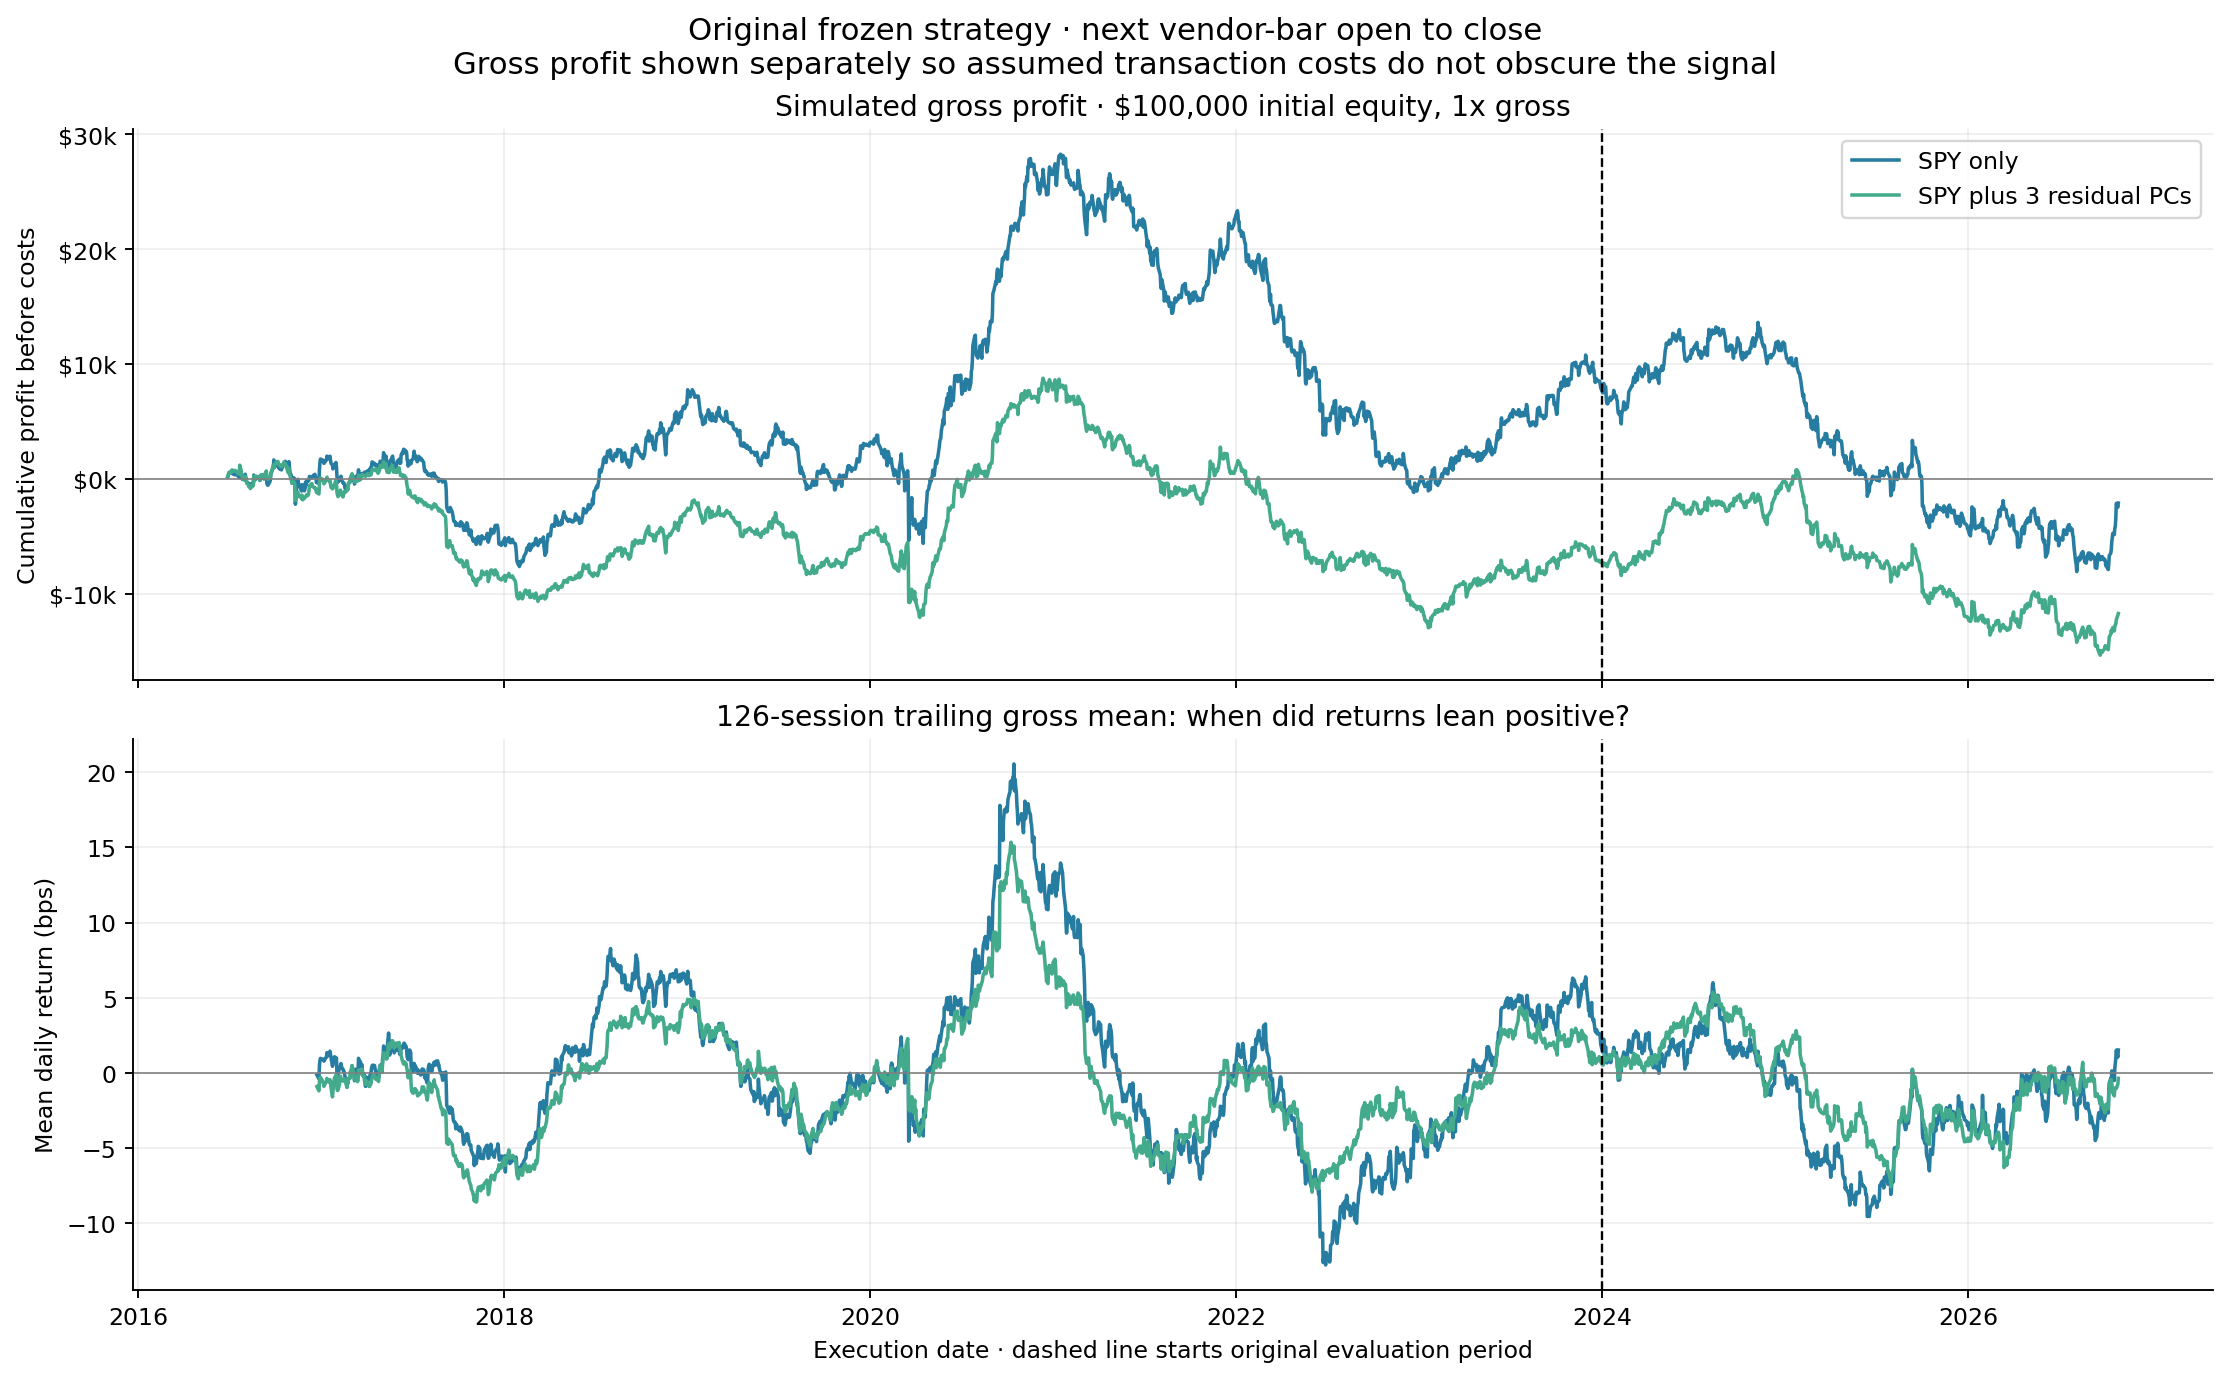

In [6]:
display(Image(filename=str(diag / "01_gross_profit.png")))

## Follow-up 2: overnight timing and simple regimes

Hypothetical close-to-next-open mean returns were negative for both original models in both periods. There is no measured aggregate positive overnight reversal that explains a missed entry opportunity. This is attribution, not an executable close-entry strategy: the exact close was already used to form the signal.

Fixed descriptive states cross 60-session SPY trend direction with 20-session annualized volatility above/below 20%. Every conditional gross-mean interval includes zero, and one later-period group contains only 14 days. These post-evaluation comparisons do not establish a validated regime switch.

,period,model,interval,mean_daily_bps,mean_daily_bps_hac95_low,mean_daily_bps_hac95_high
0,development,SPY_only,overnight_hypothetical_return,-1.658,-2.996,-0.319
1,development,SPY_only,original_intraday_raw_return,0.497,-1.346,2.339
2,development,SPY_only,close_to_close_hypothetical_return,-1.100,-3.296,1.095
3,development,SPY_plus_3_residual_PCs,overnight_hypothetical_return,-0.458,-1.428,0.512
4,development,SPY_plus_3_residual_PCs,original_intraday_raw_return,-0.347,-1.767,1.074
5,development,SPY_plus_3_residual_PCs,close_to_close_hypothetical_return,-0.748,-2.389,0.893
6,evaluation,SPY_only,overnight_hypothetical_return,-0.625,-2.481,1.231
7,evaluation,SPY_only,original_intraday_raw_return,-1.291,-4.514,1.933
8,evaluation,SPY_only,close_to_close_hypothetical_return,-1.909,-5.605,1.788
9,evaluation,SPY_plus_3_residual_PCs,overnight_hypothetical_return,-0.274,-1.789,1.242


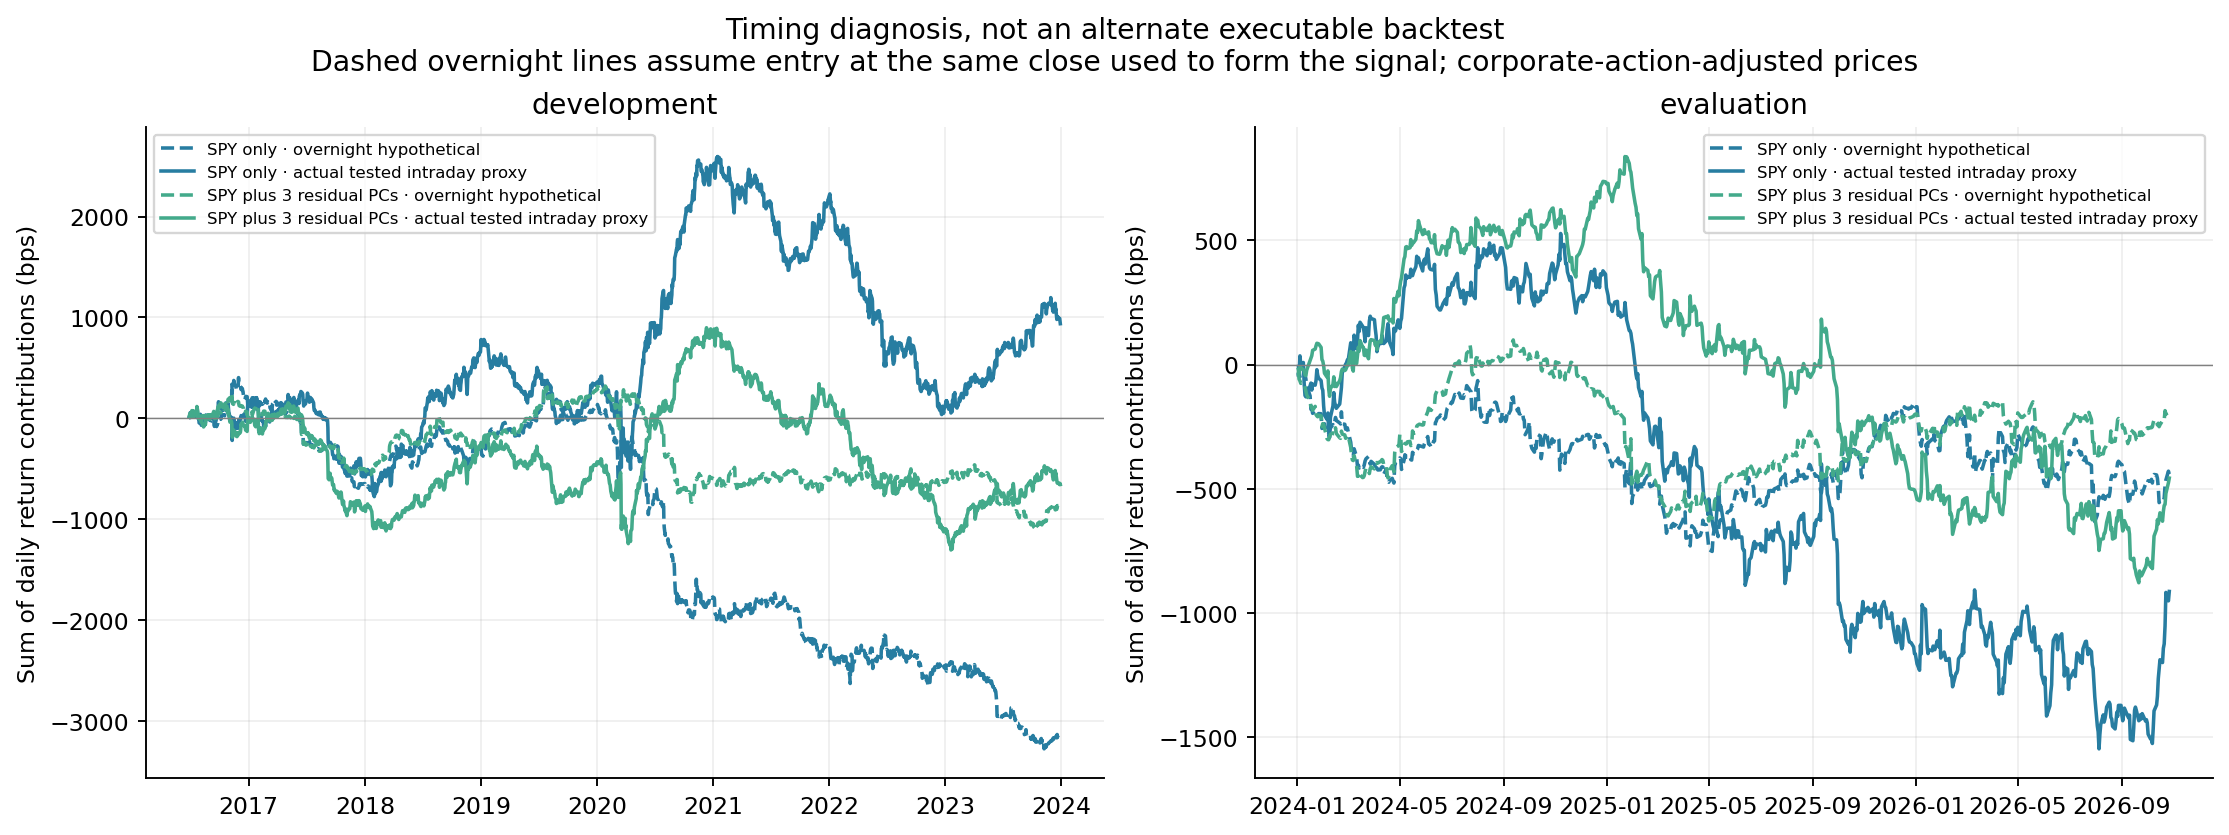

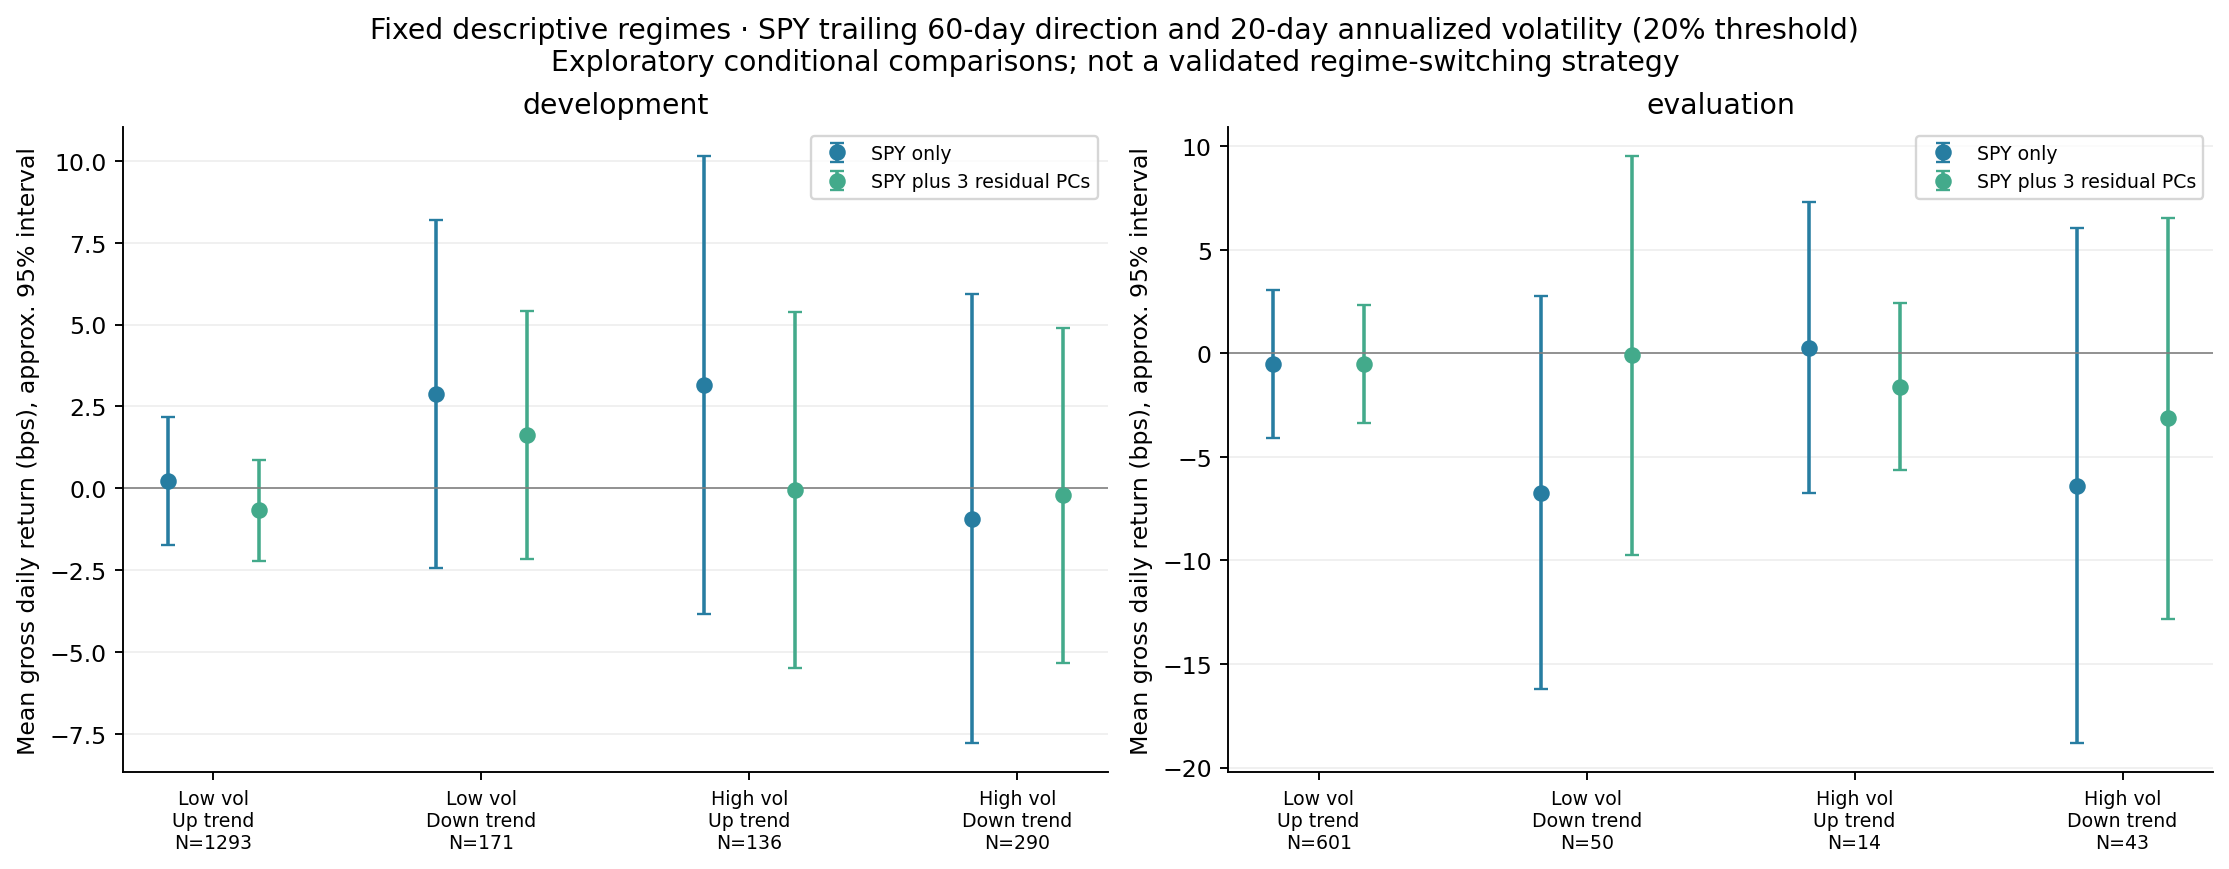

,period,model,regime,days,gross_mean_daily_bps,gross_mean_hac95_low_bps,gross_mean_hac95_high_bps,positive_gross_day_fraction
0,development,SPY_only,Low vol/Up trend,1293,0.221,-1.739,2.182,0.497
1,development,SPY_only,Low vol/Down trend,171,2.879,-2.447,8.205,0.550
2,development,SPY_only,High vol/Up trend,136,3.155,-3.832,10.142,0.522
3,development,SPY_only,High vol/Down trend,290,-0.928,-7.788,5.932,0.500
4,development,SPY_plus_3_residual_PCs,Low vol/Up trend,1293,-0.667,-2.210,0.876,0.486
5,development,SPY_plus_3_residual_PCs,Low vol/Down trend,171,1.620,-2.162,5.403,0.538
6,development,SPY_plus_3_residual_PCs,High vol/Up trend,136,-0.049,-5.480,5.382,0.493
7,development,SPY_plus_3_residual_PCs,High vol/Down trend,290,-0.217,-5.342,4.909,0.510
8,evaluation,SPY_only,Low vol/Up trend,601,-0.511,-4.078,3.057,0.459
9,evaluation,SPY_only,Low vol/Down trend,50,-6.723,-16.205,2.759,0.400


In [7]:
timing = pd.read_csv(diag / "timing_summary.csv")
display(timing[["period", "model", "interval", "mean_daily_bps", "mean_daily_bps_hac95_low", "mean_daily_bps_hac95_high"]].round(3))
display(Image(filename=str(diag / "02_timing_attribution.png")))
display(Image(filename=str(diag / "03_regimes.png")))
display(pd.read_csv(report / "conditional_regimes.csv").round(3))

## Follow-up 3: more PCs cover more variation, but did not establish positive returns

A disclosed 0/1/3/5/10 residual-PC grid holds the separate dollar/SPY constraints and all other signal/holding choices fixed. Mean combined raw training variance coverage rises from 25.5% to 80.4% in later-period windows, while every later-period gross mean remains negative. All approximate mean intervals include zero. This is an exploratory sensitivity check, not selection of an optimal component count.

The current research recommendation is to preserve this baseline and compare **labeled peer structures** on the existing panel, with manual groups, average linkage, single linkage/H0, and a PCA comparator with a similar number of exposure constraints. H0 alone reproduces single linkage. Define any additional cross-scale distinction before treating persistence as a new predictor. Then freeze the pilot design before expanding the stock universe. See [the full proposal](EQUITY_NEXT_STEPS.md).

,period,residual_pcs,gross_mean_daily_bps,gross_sharpe,gross_mean_hac95_low_bps,gross_mean_hac95_high_bps,mean_residual_standardized_variance_share,mean_combined_raw_variance_share
0,development,0,0.4966,0.1835,-1.3460,2.3391,0.0000,0.3314
1,development,1,-0.0294,-0.0133,-1.5900,1.5312,0.2194,0.4845
2,development,3,-0.3465,-0.1731,-1.7667,1.0737,0.4347,0.6167
3,development,5,0.1778,0.0978,-1.0935,1.4490,0.5513,0.6972
4,development,10,0.3601,0.2180,-0.7959,1.5161,0.7389,0.8317
5,evaluation,0,-1.2908,-0.4857,-4.5142,1.9326,0.0000,0.2550
6,evaluation,1,-0.3270,-0.1365,-3.2988,2.6448,0.2076,0.4079
7,evaluation,3,-0.6459,-0.3072,-3.2278,1.9359,0.4453,0.5603
8,evaluation,5,-0.7610,-0.3973,-3.0771,1.5552,0.5655,0.6550
9,evaluation,10,-0.6148,-0.3799,-2.5933,1.3637,0.7442,0.8041


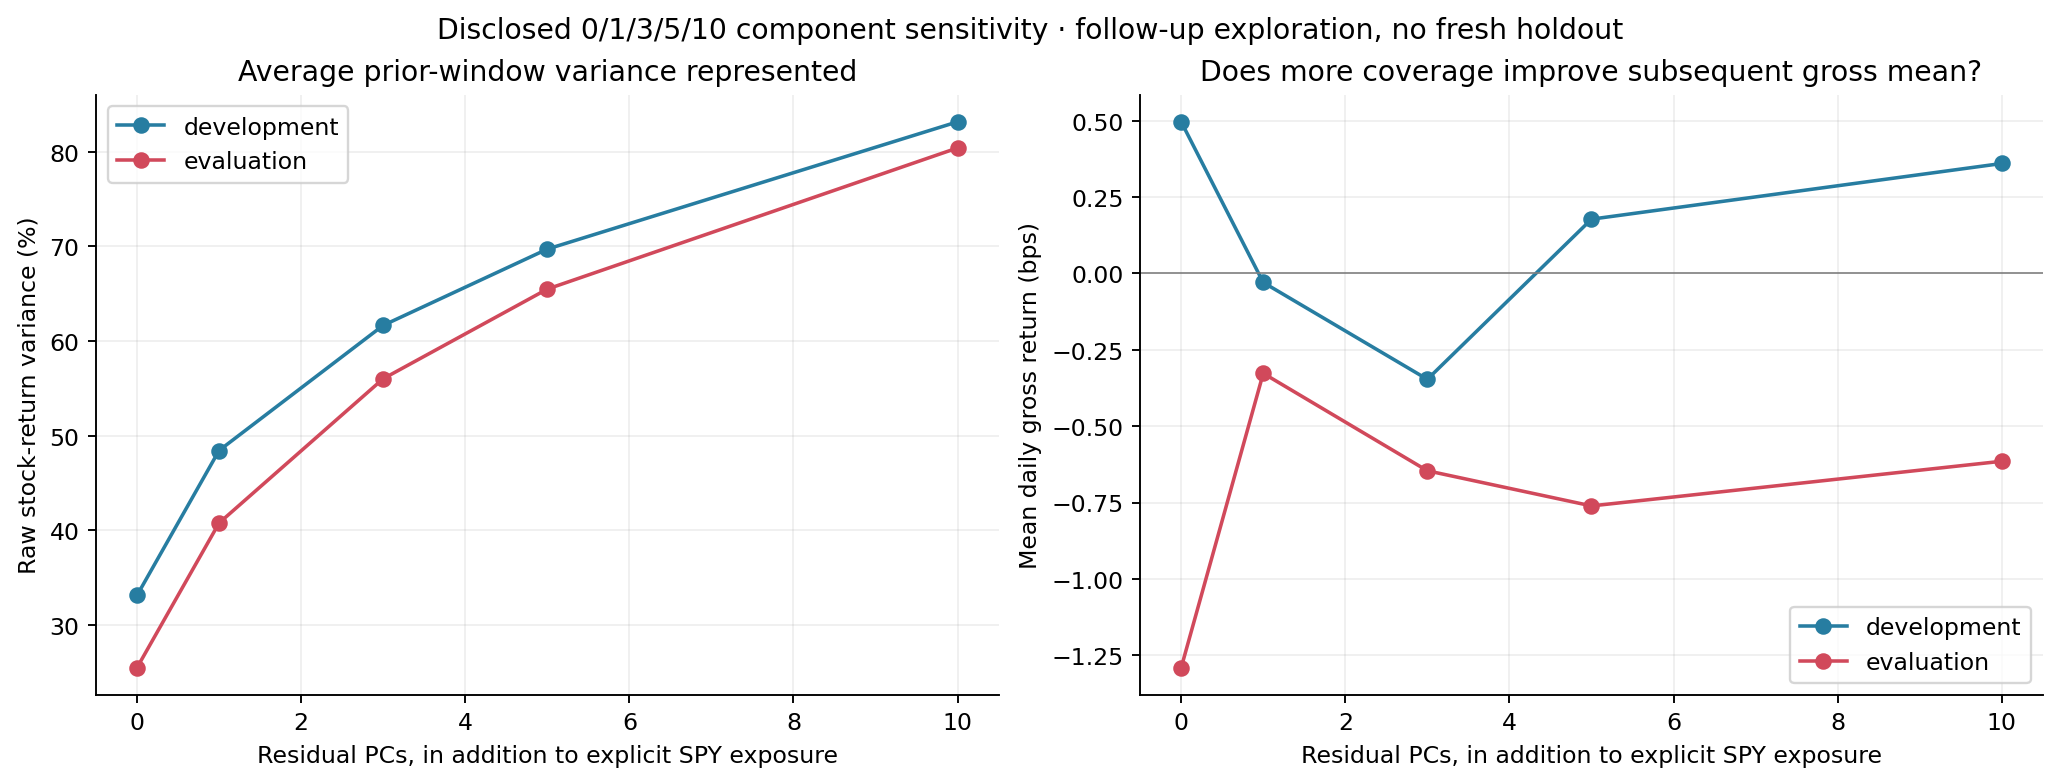

In [8]:
display(pd.read_csv(report / "component_sensitivity_summary.csv").round(4))
display(Image(filename=str(diag / "04_component_sensitivity.png")))